# Magnitude, Phase and Intelligibility of Speech

This notebook carries out the complete assignment and shows every figure, table and audio signal. The signal
processing is implemented in `phaselab.py` and each question has its own function in `experiments.py`. The full
discussion of the results is given in the report, `report/Speech_Phase_STOI_Report.pdf`.

| Question | Content | Function |
|---|---|---|
| 1 | Voice recording of about 10 s | `prepare_data` |
| 2 | STFT; magnitude MG and phase PH | `part2_stft` |
| 3 | sig1 (zero phase); PH1 and sig2 | `part3_magnitude_phase` |
| 4 | Phase pattern for a real sig2; number of patterns | `part4_realness` |
| 5 | Unintelligible version with odd random phase; recovery | `part5_window_sweep`, `part5_scramble_recover` |
| 6 | NOISEX-92 noise, STOI, Questions 2 to 5 repeated, band-pass filter | `make_noisy`, `part6_*` |

Analysis settings: sampling rate 16 kHz, Hann window of 512 samples (32 ms), hop of 128 samples (8 ms, 75 %
overlap), two-sided DFT, least-squares inverse STFT.

In [1]:
import io
import json

import pandas as pd
from IPython.display import Audio, Image, display
from PIL import Image as PILImage

import experiments as E

pd.set_option("display.precision", 3)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)


def show(path, width=900):
    # figures are embedded as compressed JPEG so that the executed notebook stays small
    im = PILImage.open(path).convert("RGB")
    if im.width > 1300:
        im = im.resize((1300, round(im.height * 1300 / im.width)), PILImage.LANCZOS)
    buf = io.BytesIO()
    im.save(buf, "JPEG", quality=72)
    display(Image(data=buf.getvalue(), format="jpeg", width=width))


EMBED_AUDIO = False   # True shows audio players, but makes the saved notebook much larger


def play(folder, name):
    path = E.AUD / folder / f"{name}.wav"
    print(name, "->", path.relative_to(E.ROOT).as_posix())
    if EMBED_AUDIO:
        display(Audio(str(path)))

## Question 1: Voice recording

In [2]:
info = E.prepare_data()
x = E.load_clean()
print(json.dumps(info, indent=1))
play("clean", "original")

{
 "speech_id": "1272-128104-0003",
 "duration_s": 9.9,
 "fs": 16000,
 "transcript": "HE HAS GRAVE DOUBTS WHETHER SIR FREDERICK LEIGHTON'S WORK IS REALLY GREEK AFTER ALL AND CAN DISCOVER IN IT BUT LITTLE OF ROCKY ITHACA",
 "noise_white": {
  "orig_fs": 19980,
  "orig_subtype": "PCM_16",
  "duration_s": 235.23
 },
 "noise_babble": {
  "orig_fs": 19980,
  "orig_subtype": "PCM_16",
  "duration_s": 235.23
 },
 "noise_machinegun": {
  "orig_fs": 8000,
  "orig_subtype": "PCM_U8",
  "duration_s": 235.23
 },
 "speech_dynamic_range_dB": 47.07844873635142
}
original -> outputs/audio/clean/original.wav


The recording is LibriSpeech dev-clean utterance 1272-128104-0003 (male speaker, 9.9 s, 16 kHz, lossless). The
loudest speech frames are about 47 dB above the pauses, so the background noise is negligible.

## Question 2: STFT magnitude and phase

X shape (bins x frames): (512, 1241)


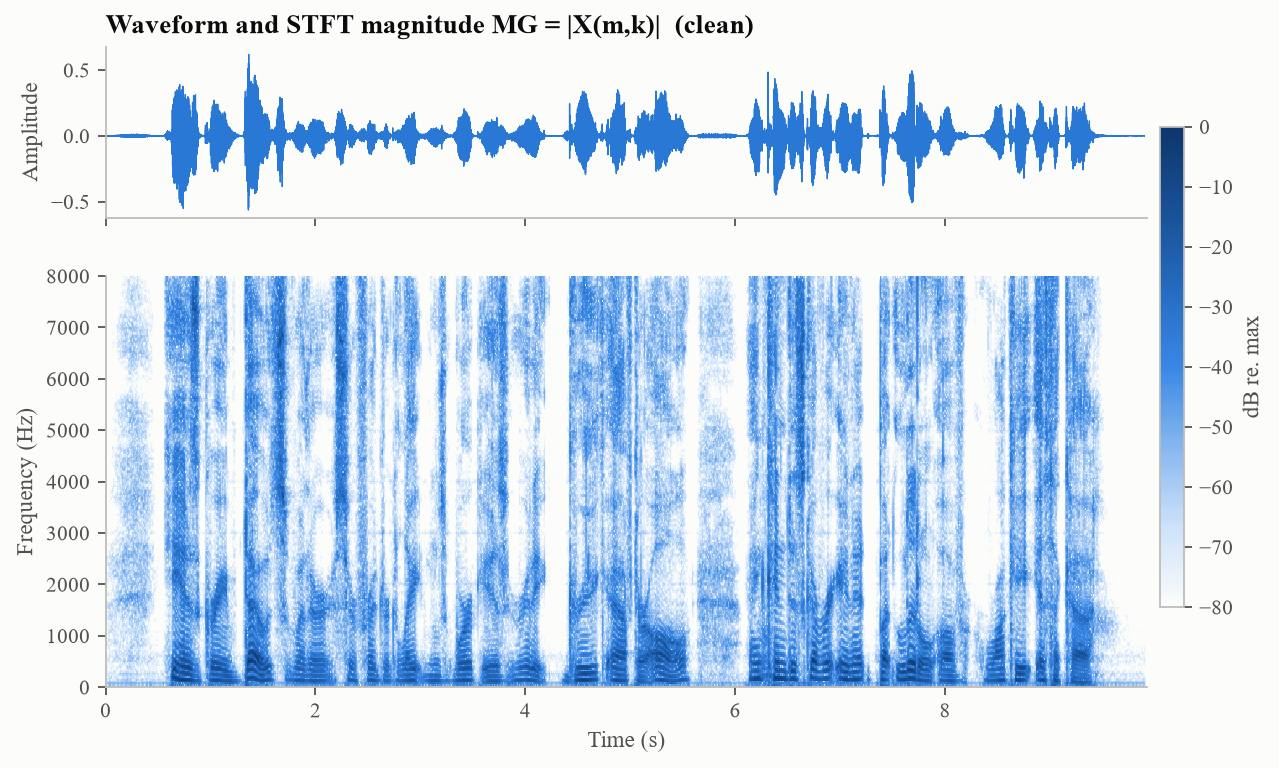

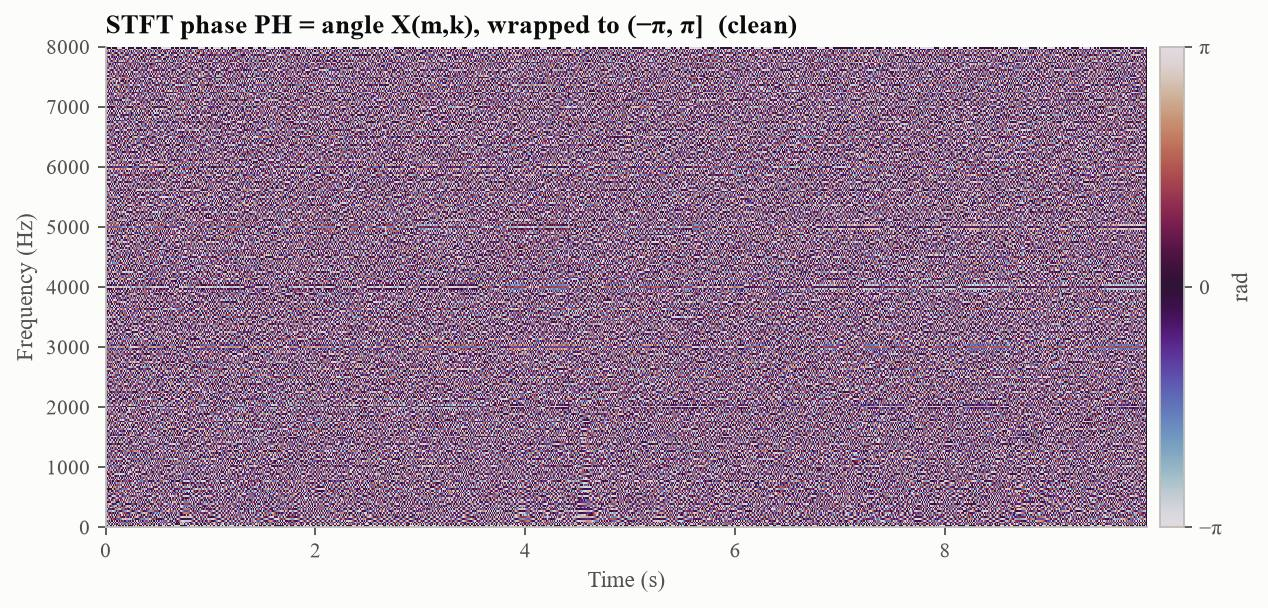

In [3]:
p2 = E.part2_stft(x, "clean")
print("X shape (bins x frames):", p2["shape"])
show(p2["figs"]["MG"])
show(p2["figs"]["PH"])

The magnitude shows harmonics, formants, fricatives and pauses. The wrapped phase looks like noise because the phase
of each bin advances by 2πkH/N per hop and wraps at its own rate; its time and frequency derivatives, shown next, are
clearly structured. Every frame has an even magnitude and an odd phase, which is the basis of Questions 3 and 4.

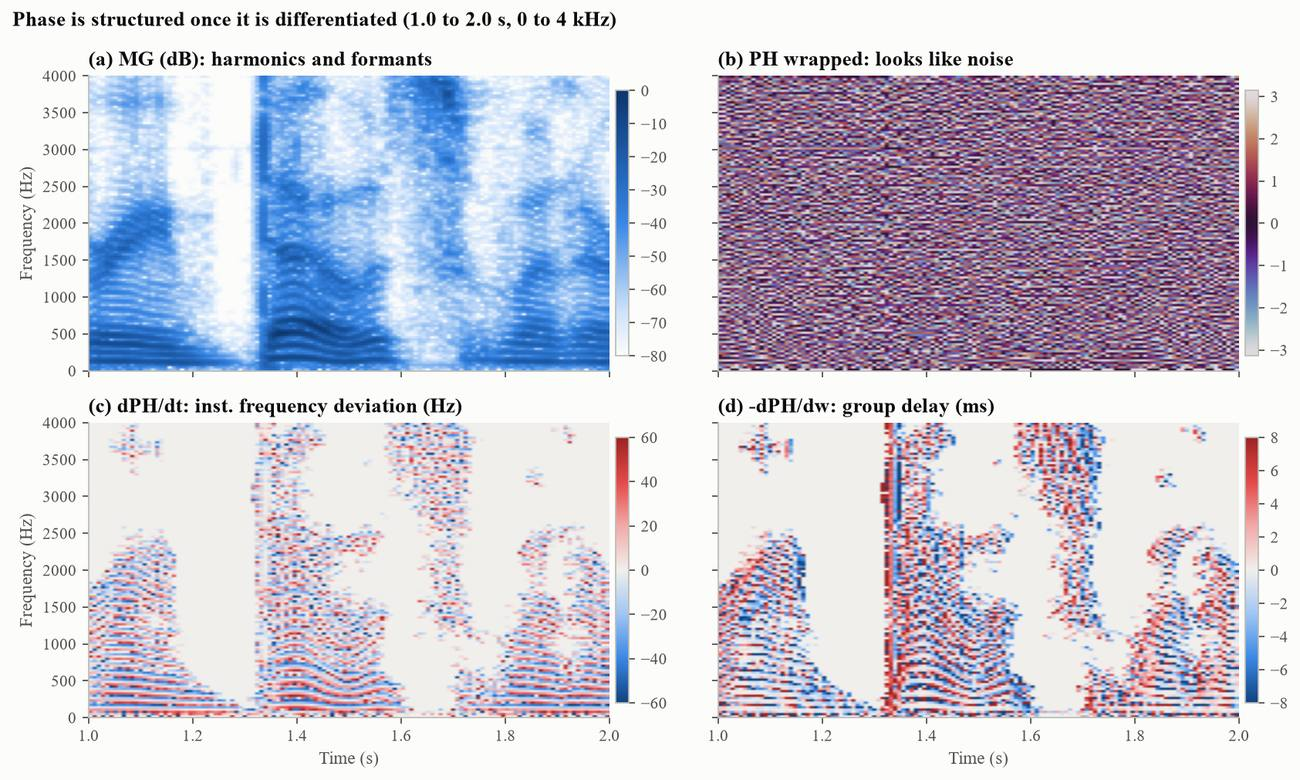

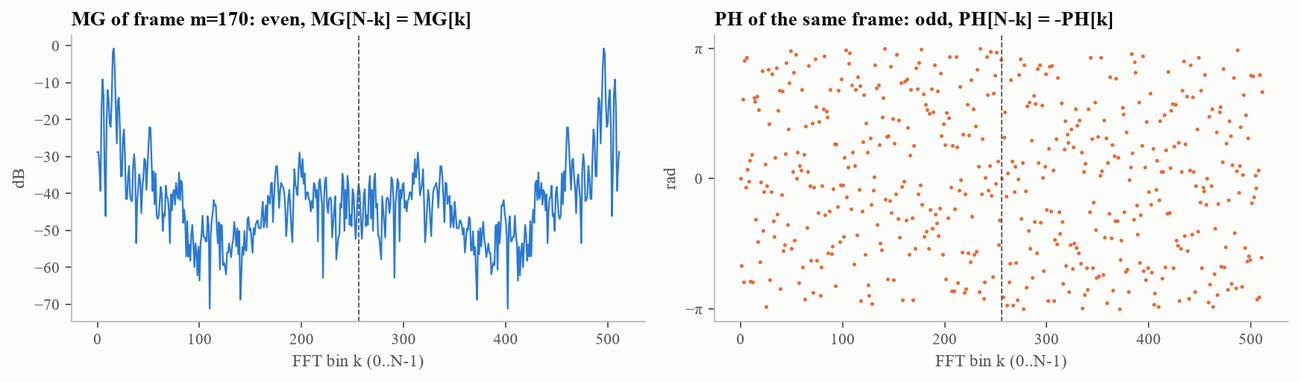

In [4]:
show(p2["figs"]["phase_structure"])
show(p2["figs"]["symmetry"])

## Question 3: sig1 (zero phase) and sig2 (phase array PH1)

In [5]:
p3 = E.part3_magnitude_phase(x, p2["X"], "clean")
display(p3["metrics"])
display(pd.Series(p3["realness"], name="realness checks").to_frame())
display(p3["wstats"])

,energy_ratio_dB,corr,SNR_dB,SC,LSD_dB,STOI,ESTOI
variant,,,,,,,
sig1 (zero phase),-13.788,0.040,7.015e-03,0.693,6.994,0.839,0.731
sig1c (zero phase about window centre),-1.969,0.045,8.761e-03,0.596,7.103,0.945,0.889
sig2 unconstrained PH1: real part,-8.900,-0.046,9.055e-03,0.578,6.011,0.870,0.776
sig2 odd-symmetric PH1,-6.266,0.011,4.828e-04,0.562,5.996,0.871,0.774
control: phase only (MG = 1),-0.697,0.257,2.970e-01,1.216,29.232,0.527,0.266


,realness checks
sig1_max_abs_imag,0.0
sig2_unconstrained_imag_energy_ratio,0.517
sig2_unconstrained_max_abs_imag,0.324
sig2_odd_max_abs_imag,0.0
PH1_unconstrained_is_hermitian,False
PH1_odd_is_hermitian,True


,kurtosis,crest_dB,autocorr_at_lag_H
original,10.731,18.811,0.306
sig1,22.683,22.775,0.857
sig1c,22.883,23.404,0.959
sig2,12.917,20.266,0.052


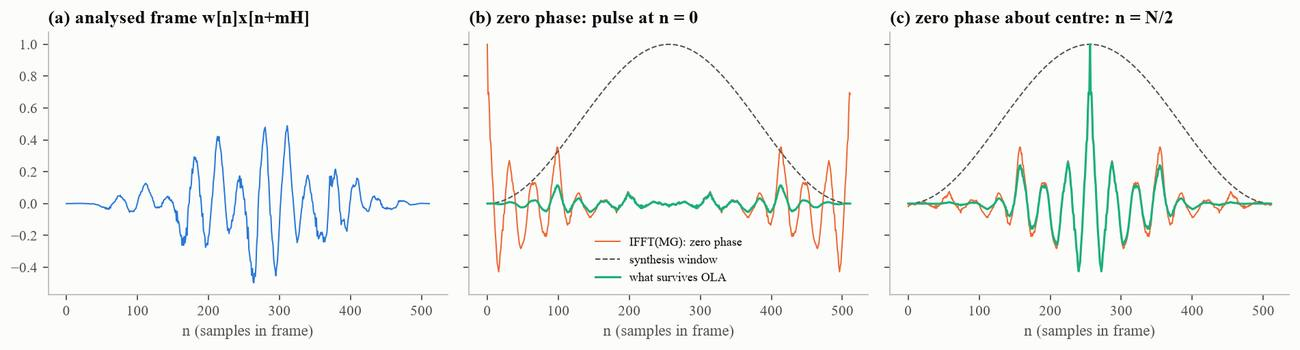

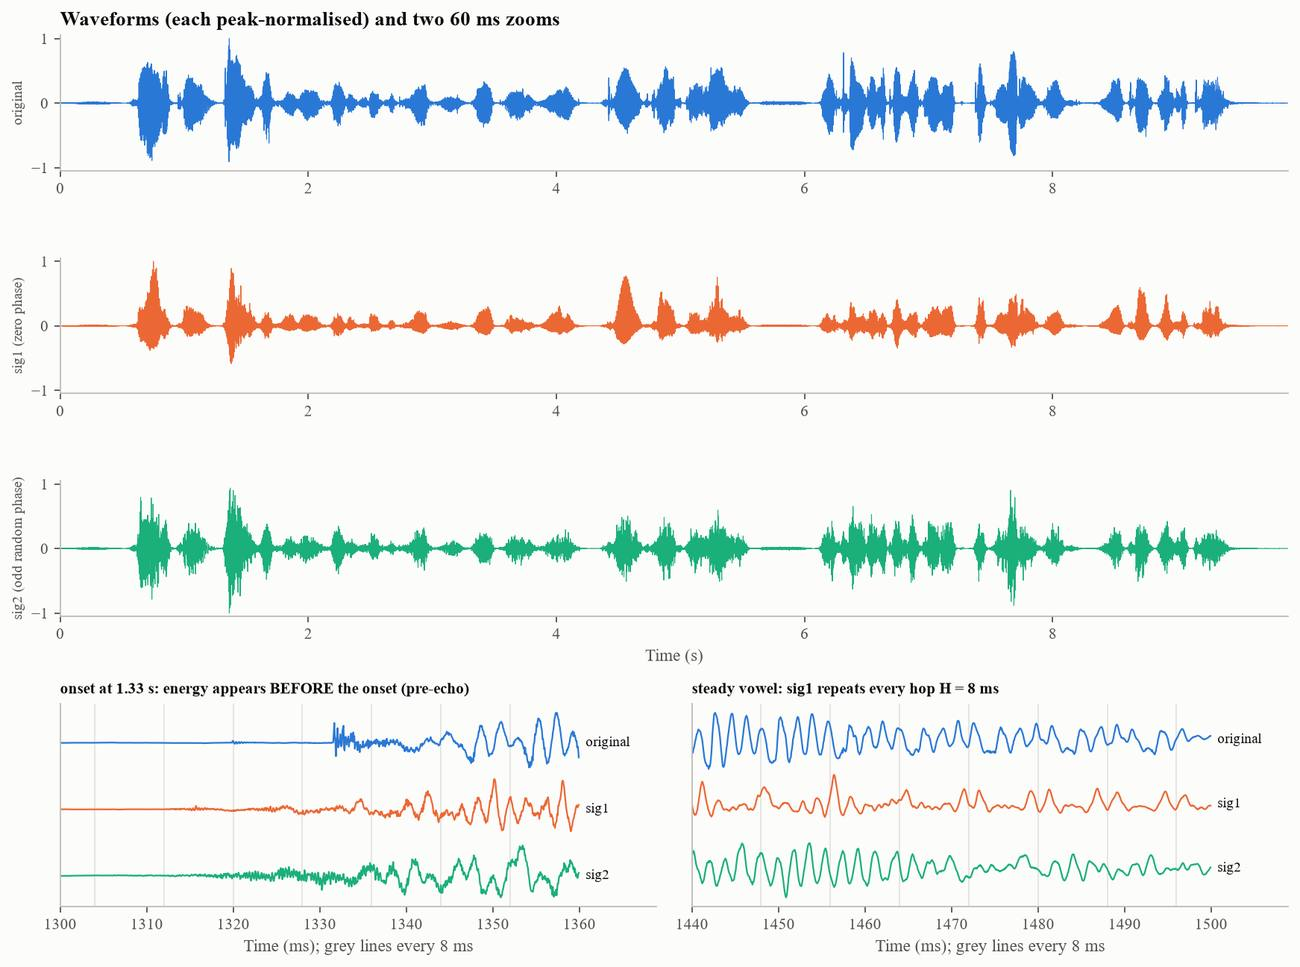

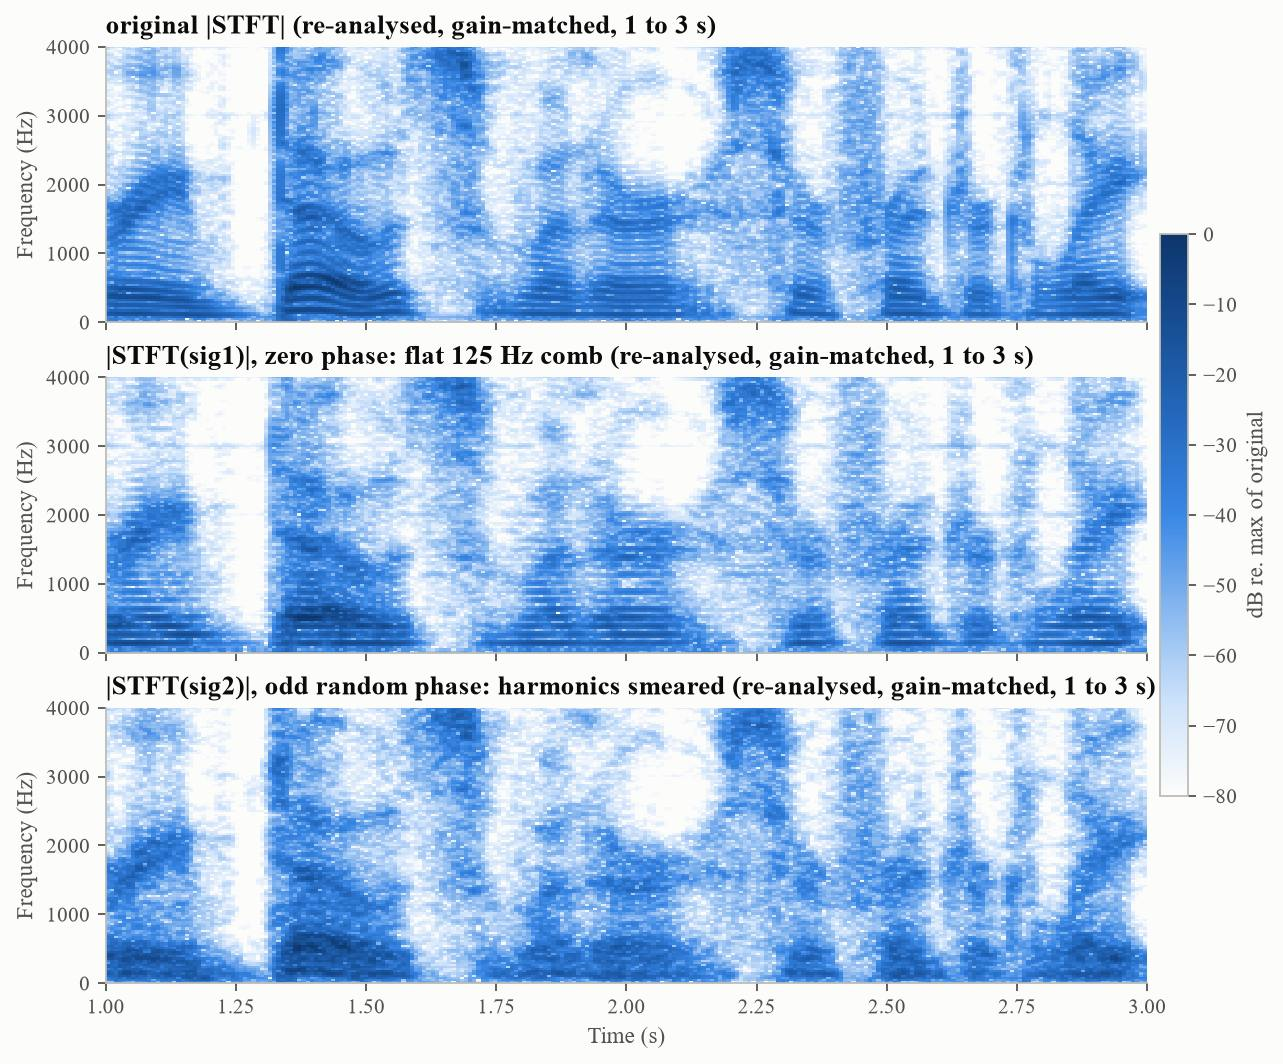

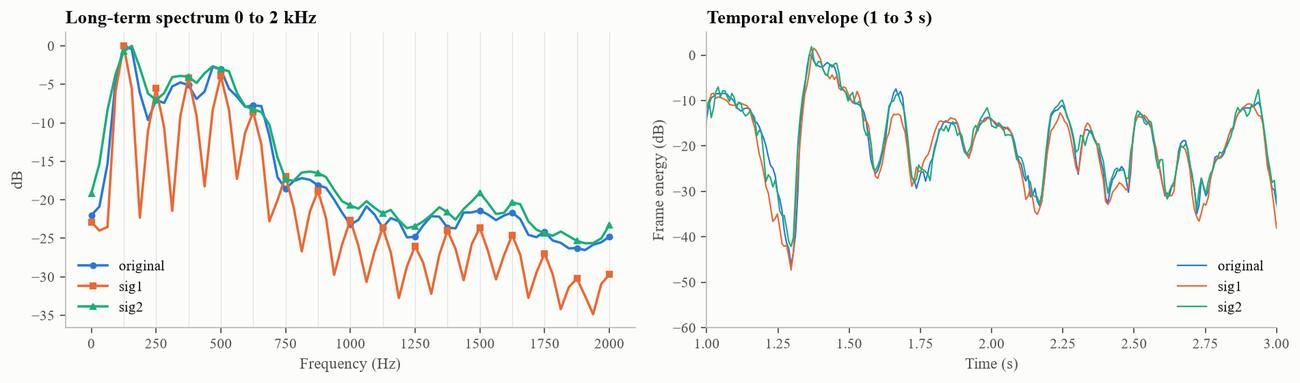

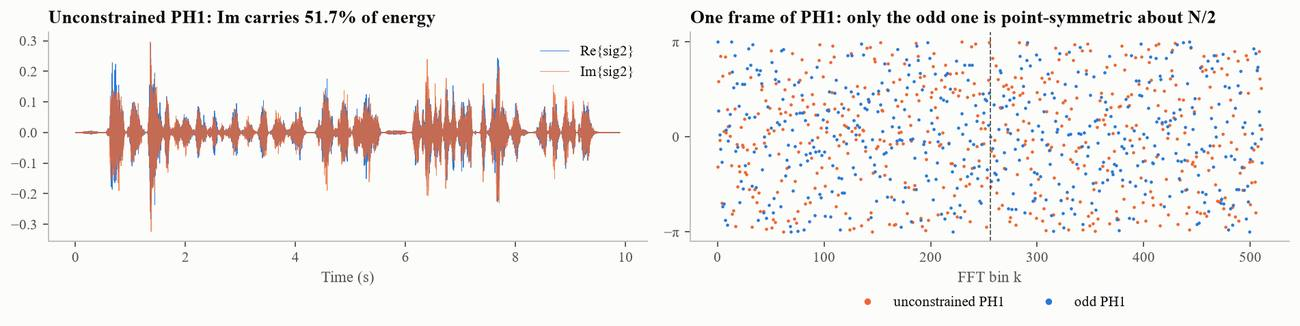

sig1_zero_phase -> outputs/audio/clean/sig1_zero_phase.wav
sig1c_zero_phase_centred -> outputs/audio/clean/sig1c_zero_phase_centred.wav
sig2_odd_random_phase -> outputs/audio/clean/sig2_odd_random_phase.wav
sig2_unconstrained_real_part -> outputs/audio/clean/sig2_unconstrained_real_part.wav
control_phase_only -> outputs/audio/clean/control_phase_only.wav


In [6]:
for key in ["frame_zero_phase", "waveforms", "specs", "ltas_env", "complex_sig2"]:
    show(p3["figs"][key])
for name in ["sig1_zero_phase", "sig1c_zero_phase_centred", "sig2_odd_random_phase",
             "sig2_unconstrained_real_part", "control_phase_only"]:
    play("clean", name)

* sig1: zero phase turns every frame into a symmetric pulse at the frame origin. The pulses repeat every hop, so sig1
  is a buzzy monotone at fs/H = 125 Hz with the correct formants, and its waveform is uncorrelated with the original.
* With an unconstrained PH1, sig2 is complex (about half of its energy is imaginary). It is real only if PH1 is
  odd-symmetric (Question 4). The real sig2 is rough and noise-like and keeps about H/N = 1/4 of the energy.
* sig1 and sig2 have the same magnitude; sig1 is coherent and periodic, sig2 incoherent and aperiodic.

## Question 4: Phase pattern that guarantees a real sig2

,PH1 pattern,trials,imag/total energy (mean),max |Im{sig2}|,real?
0,zero phase (PH1 = 0),1,1.276e-31,6.910e-17,True
1,"linear phase (pure delay, −2πkd/N)",1,5.241e-28,3.630e-15,True
2,"odd random, DC and Nyquist in {0, π}",20,2.675e-32,9.564e-17,True
3,"odd random, DC and Nyquist arbitrary",20,2.750e-04,9.743e-03,False
4,odd random + constant π/4,20,5.000e-01,3.188e-01,False
5,even random (wrong symmetry),20,4.997e-01,3.667e-01,False
6,unconstrained i.i.d. uniform,20,4.936e-01,3.616e-01,False


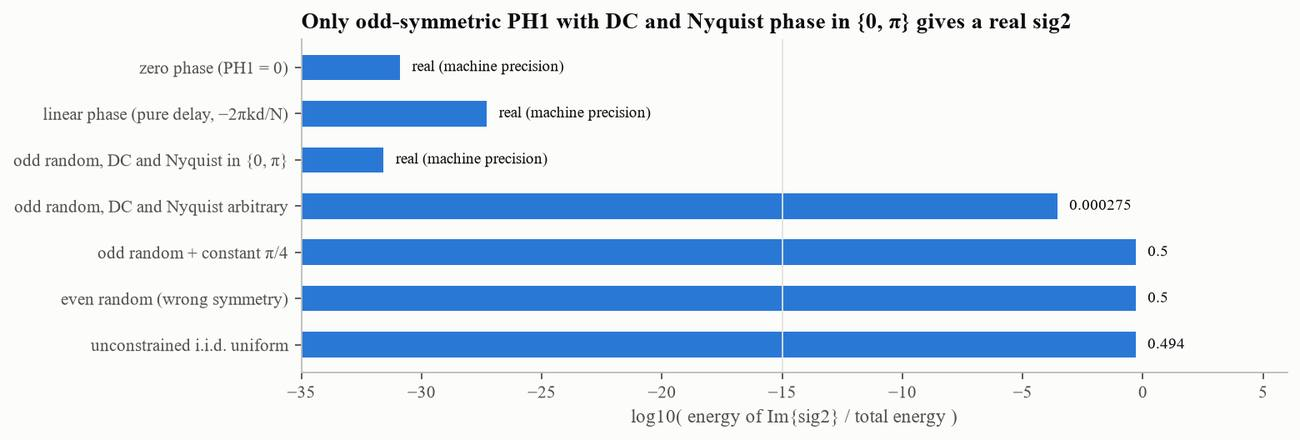

{
 "N": 512,
 "frames_M": 1241,
 "free_phases_per_frame": 255,
 "binary_choices_per_frame": 4,
 "real_degrees_of_freedom_total": 316455,
 "log10_patterns_1bit": {
  "per_frame": 77.36470888564317,
  "whole_signal": 96009.60372708317
 },
 "log10_patterns_3bit": {
  "per_frame": 230.8900066742736,
  "whole_signal": 286534.49828277354
 },
 "log10_patterns_8bit": {
  "per_frame": 614.7032511458495,
  "whole_signal": 762846.7346719992
 },
 "log10_patterns_16bit": {
  "per_frame": 1228.8044423003712,
  "whole_signal": 1524946.3128947606
 }
}


In [7]:
p4 = E.part4_realness(p2["MG"])
display(p4["table"])
show(p4["figs"]["realness"])
print(json.dumps(p4["count"], indent=1, default=float))

A real sig2 requires PH1(m, N−k) = −PH1(m, k) for k = 1, ..., N/2−1 and PH1(m, 0), PH1(m, N/2) equal to 0 or π in
every frame. N/2−1 = 255 phases per frame remain free, so there are infinitely many valid patterns.

## Question 5: Unintelligible version with odd random phase, and recovery

,window_ms,N,STOI scrambled,ESTOI scrambled,STOI blind GLA,ESTOI blind GLA,STOI GLA true MG,ESTOI GLA true MG,STOI keyed OTP scrambled,ESTOI keyed OTP scrambled,energy scrambled/original dB
0,16.0,256,0.877,0.777,0.878,0.778,0.994,0.987,0.823,0.655,-6.187
1,32.0,512,0.879,0.792,0.878,0.791,0.999,0.996,0.801,0.661,-5.998
2,64.0,1024,0.825,0.727,0.825,0.726,0.997,0.991,0.708,0.565,-6.259
3,128.0,2048,0.754,0.608,0.750,0.608,0.991,0.974,0.592,0.387,-6.212
4,256.0,4096,0.637,0.443,0.641,0.443,0.976,0.942,0.463,0.186,-5.780
5,512.0,8192,0.480,0.219,0.482,0.223,0.931,0.850,0.380,0.067,-5.865
6,1024.0,16384,0.391,0.076,0.395,0.073,0.841,0.700,0.357,-0.003,-5.980
7,2048.0,32768,0.361,0.006,0.379,0.016,0.734,0.541,0.348,-0.029,-5.967


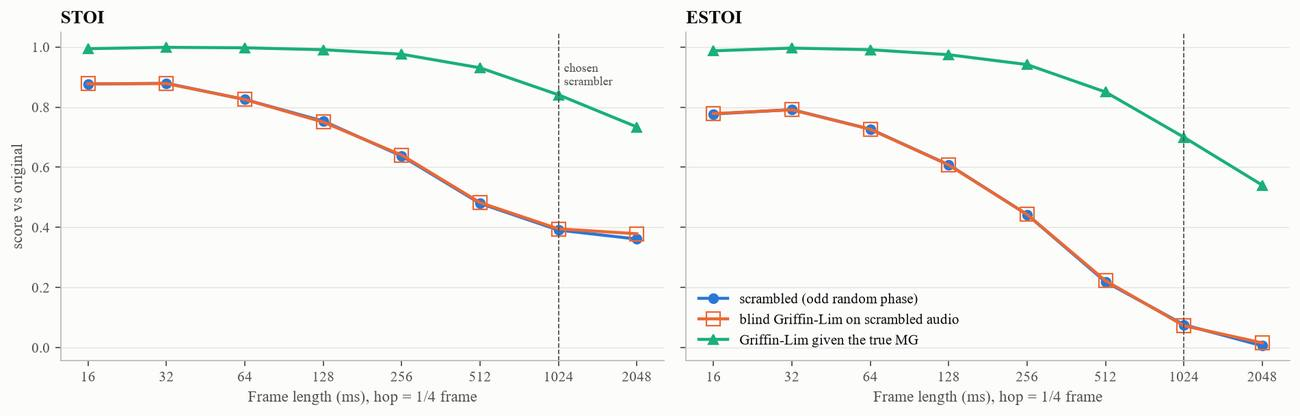

In [8]:
sw = E.part5_window_sweep(x)
display(sw["table"])
show(sw["figs"]["sweep"])

,STOI,ESTOI,SNR_vs_input_dB
scrambled (replace phase),0.396,0.072,7.859e-03
R1 blind Griffin-Lim,0.395,0.061,9.091e-04
R2 Griffin-Lim with true MG,0.999,0.998,1.796e-02
scrambled (keyed one-time pad),0.357,-0.003,6.221e-06
R3 keyed descramble,1.000,1.000,2.290e+02


{'_imag_max_scrambled': 5.515337314120211e-17, '_SC_blind_vs_true_MG': 0.6251886985565133, '_SC_scrambled_vs_true_MG': 0.5353754714801644}


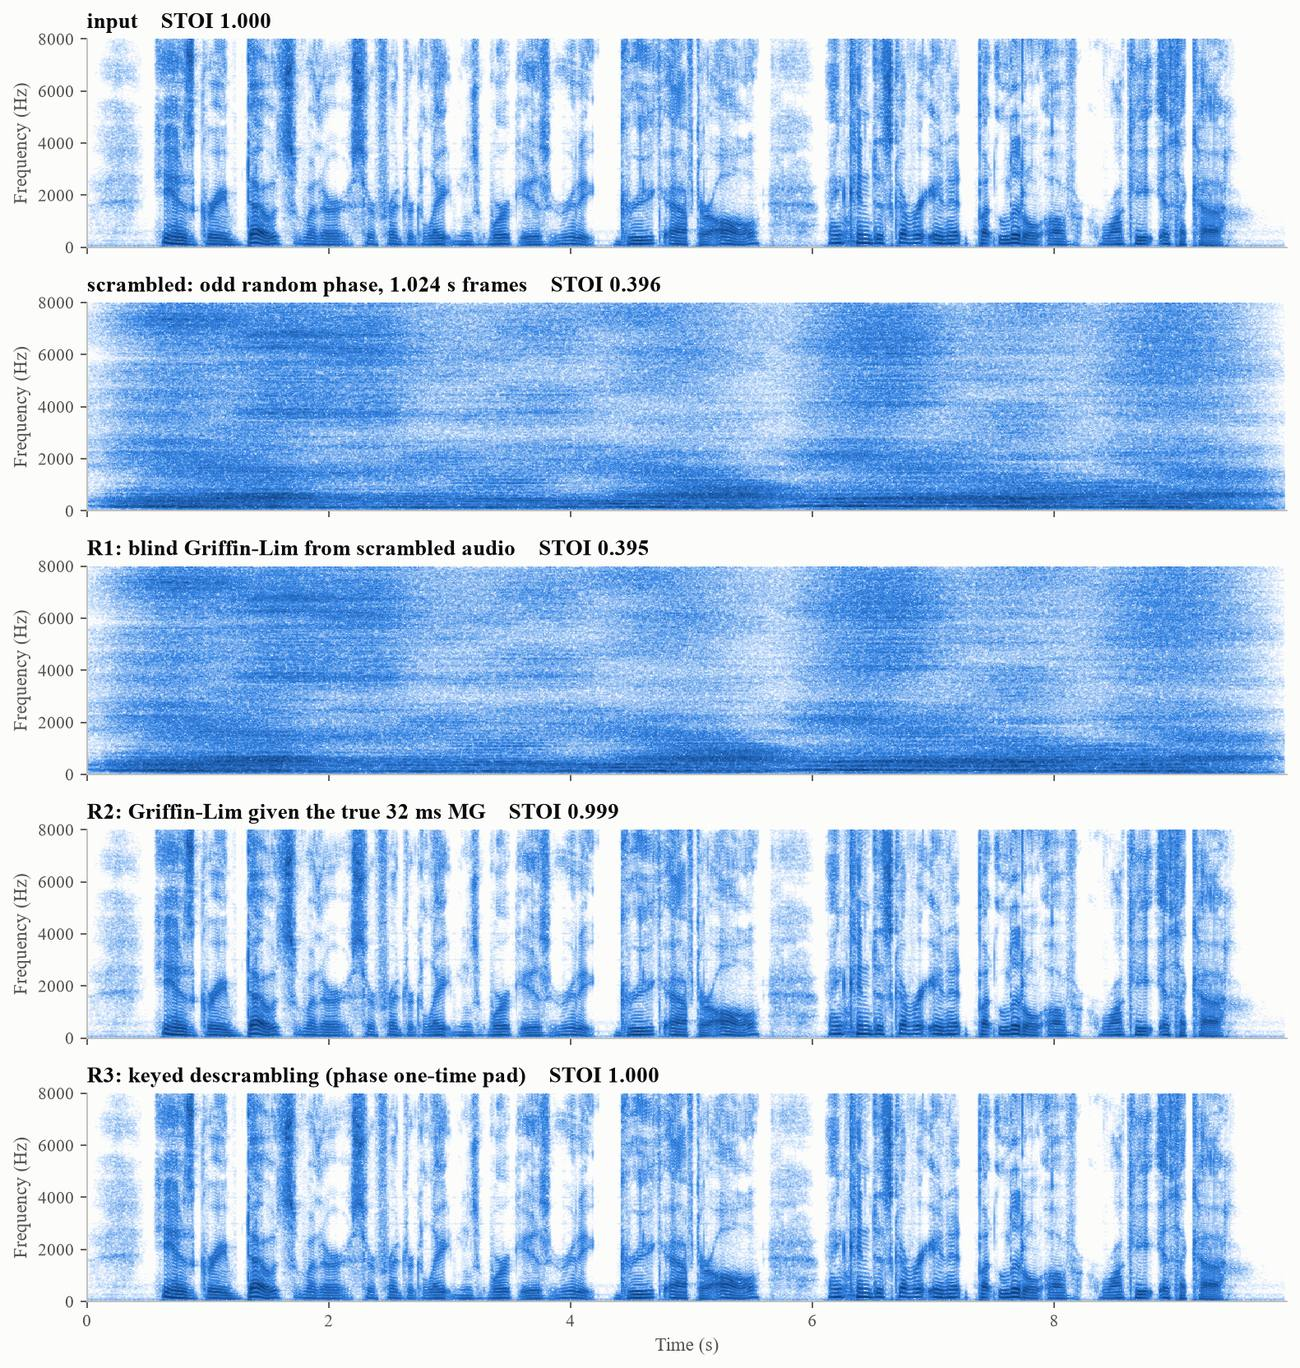

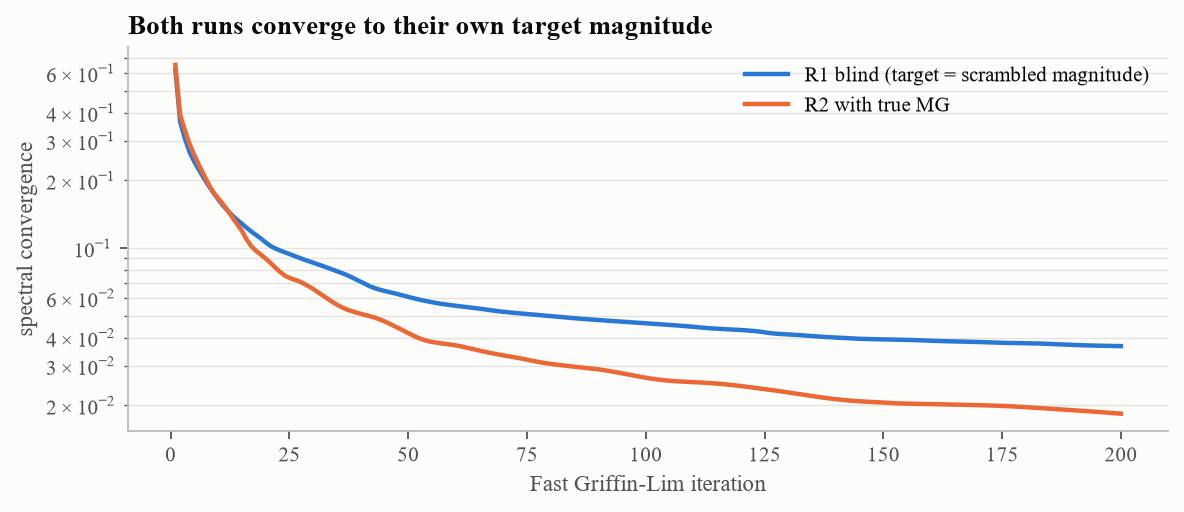

scrambled_odd_random_phase_1s -> outputs/audio/clean/scrambled_odd_random_phase_1s.wav
recovered_R1_blind_griffin_lim -> outputs/audio/clean/recovered_R1_blind_griffin_lim.wav
recovered_R2_griffin_lim_true_MG -> outputs/audio/clean/recovered_R2_griffin_lim_true_MG.wav
scrambled_keyed_otp_1s -> outputs/audio/clean/scrambled_keyed_otp_1s.wav
recovered_R3_keyed -> outputs/audio/clean/recovered_R3_keyed.wav


In [9]:
p5 = E.part5_scramble_recover(x, x, "clean", detailed=True)
display(pd.DataFrame({k: v for k, v in p5["metrics"].items() if not k.startswith("_")}).T)
print({k: v for k, v in p5["metrics"].items() if k.startswith("_")})
show(p5["figs"]["recovery_specs"])
show(p5["figs"]["gla_convergence"], 700)
for name in ["scrambled_odd_random_phase_1s", "recovered_R1_blind_griffin_lim", "recovered_R2_griffin_lim_true_MG",
             "scrambled_keyed_otp_1s", "recovered_R3_keyed"]:
    play("clean", name)

With 32 ms frames the random-phase version remains intelligible, so the scrambler uses 1.024 s frames (ESTOI close to
zero). Blind recovery is impossible because the scrambled signal is itself a consistent solution for its own
magnitude; recovery succeeds with the true magnitude as side information, and exactly with a key.

## Question 6: NOISEX-92 noise, STOI, repetition of Questions 2 to 5, band-pass filtering

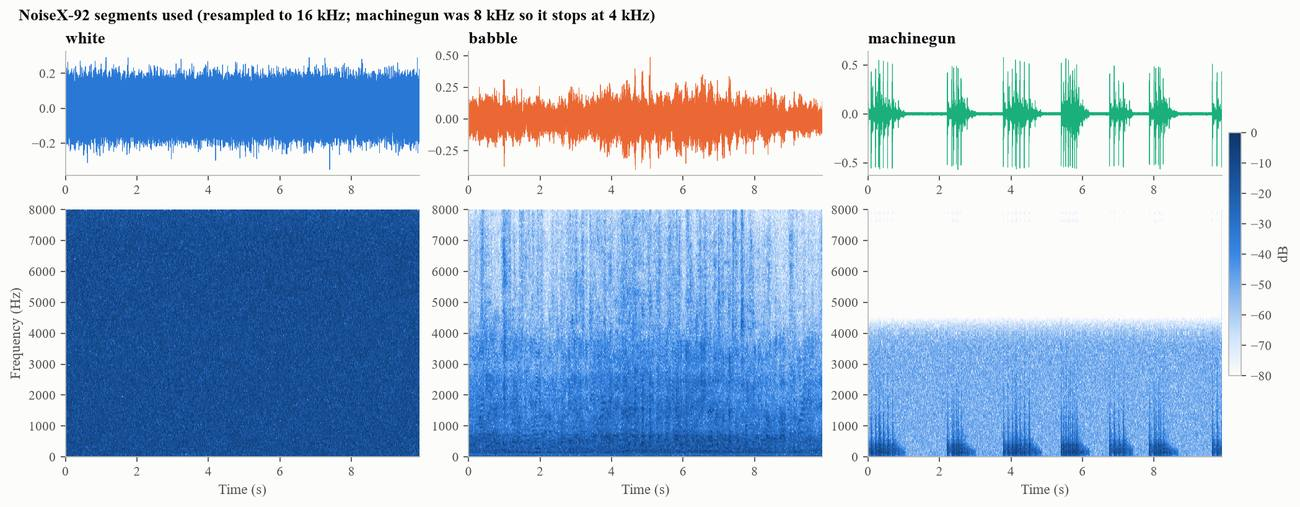

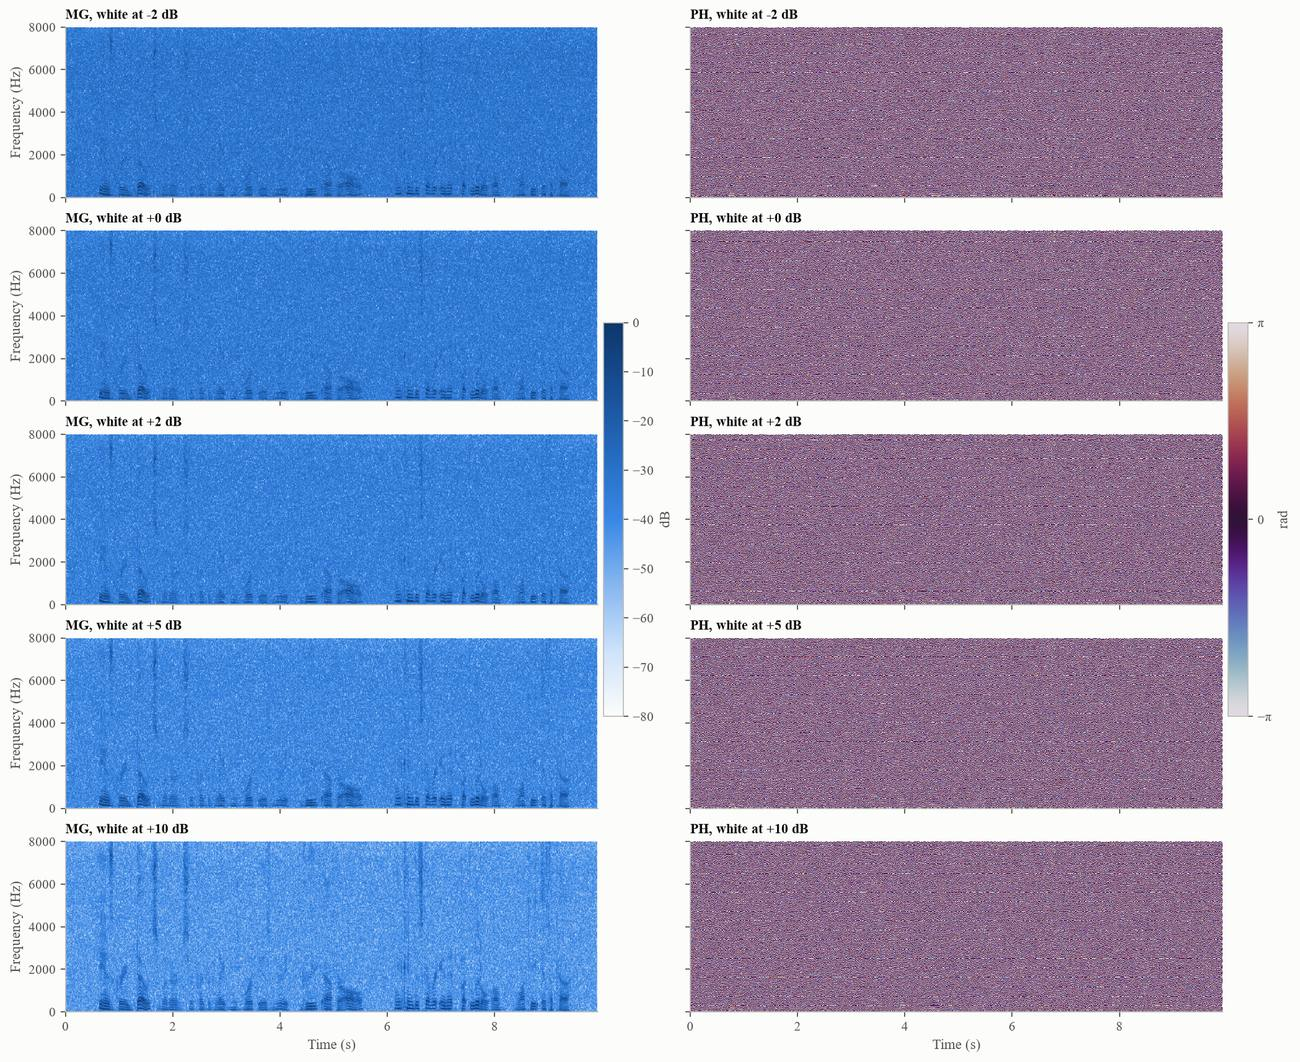

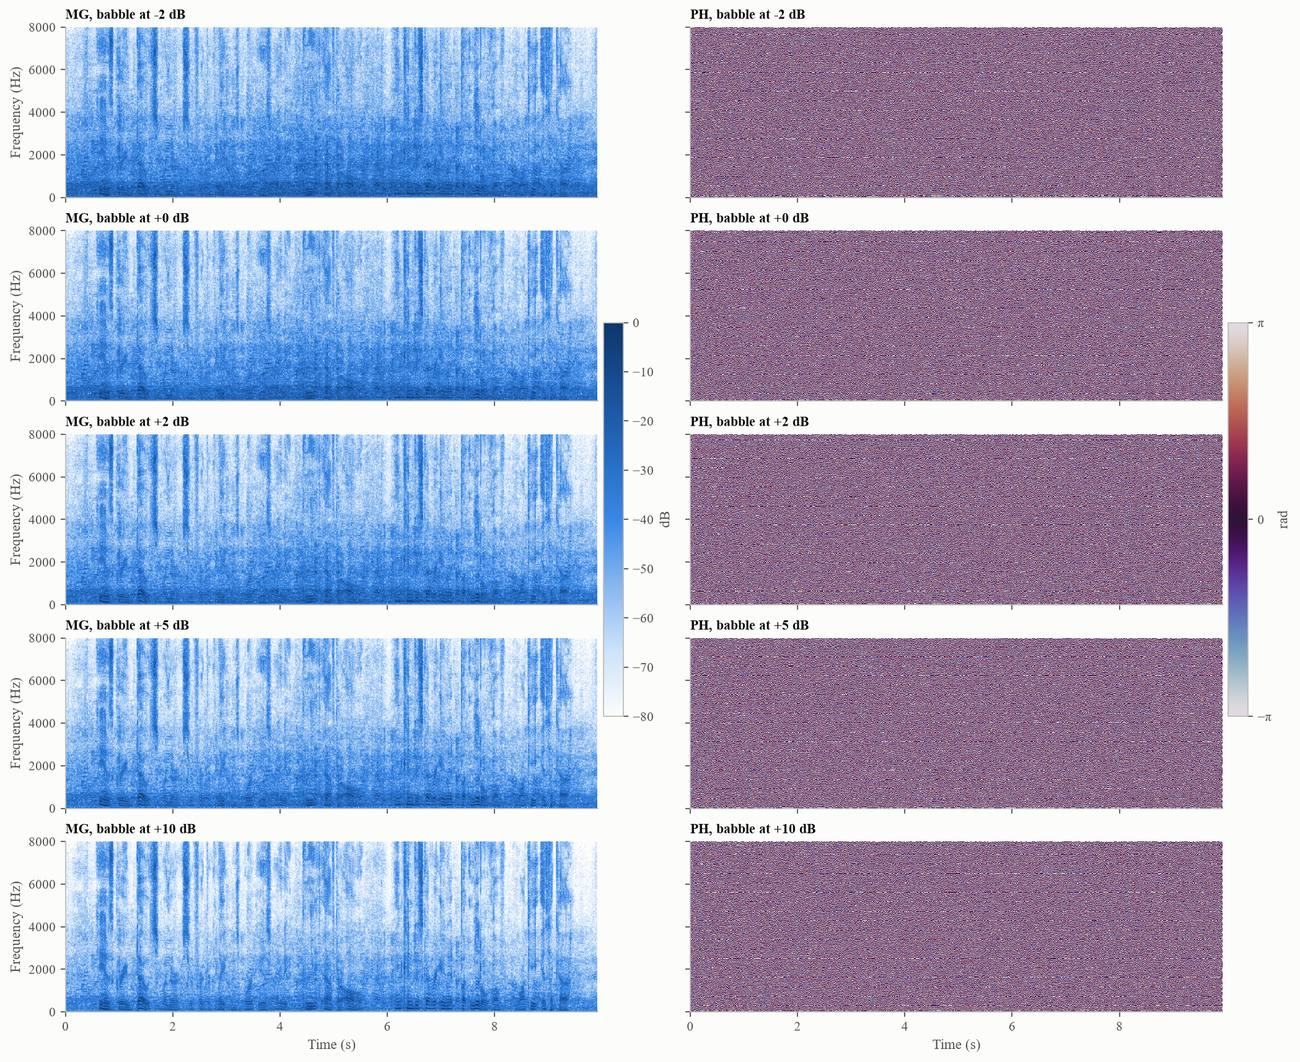

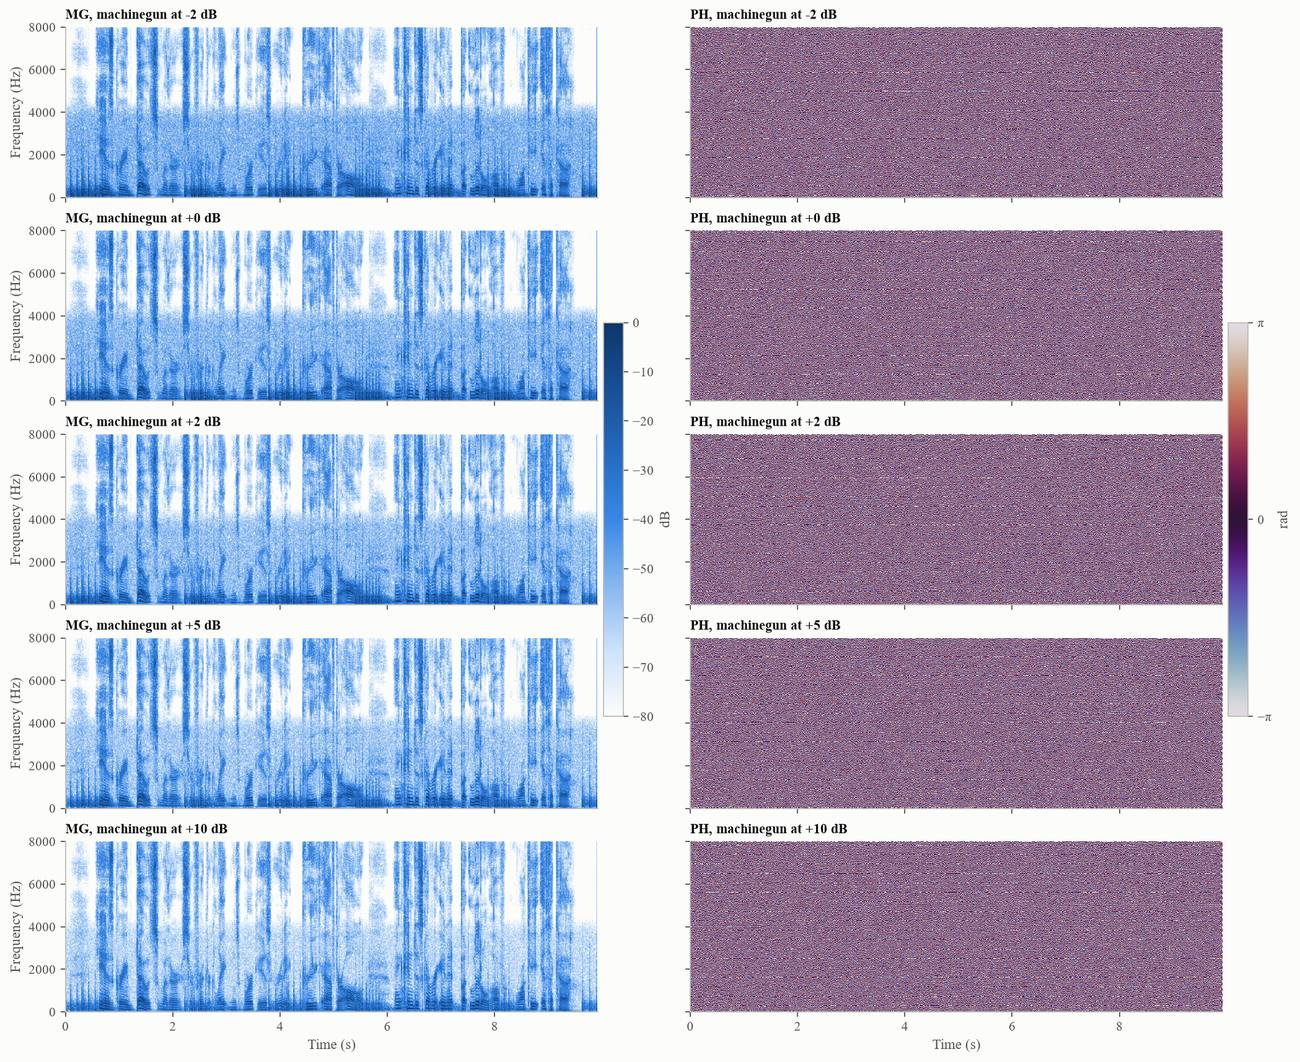

In [10]:
noisy = E.make_noisy(x)
f6 = E.part6_noise_figs(x, noisy)
show(f6["noises"])
for n in E.NOISES:
    show(f6[f"MG_PH_{n}"], 950)

noisy  sig1 (zero phase)  sig2 (odd random phase)  scrambled (replace phase)  R1 blind Griffin-Lim  R2 Griffin-Lim with true MG  scrambled (keyed one-time pad)  \
noise      SNR_dB                                                                                                                                                                    
white      -2      0.676              0.576                    0.579                      0.378                 0.371                        0.676                           0.357   
            0      0.712              0.602                    0.608                      0.380                 0.376                        0.711                           0.357   
            2      0.747              0.629                    0.636                      0.381                 0.380                        0.748                           0.357   
            5      0.798              0.669                    0.678                      0.384                 0.382                        0.798                           0.356   
            10     0.872              0.729                    0.743                      0.390                 0.388                        0.872                           0.356   
babble     -2      0.587              0.505                    0.513                      0.376                 0.377                        0.586                           0.358   
            0      0.638              0.545                    0.556                      0.379                 0.374                        0.638                           0.359   
            2      0.690              0.586                    0.599                      0.383                 0.371                        0.688                           0.359   
            5      0.765              0.646                    0.663                      0.388                 0.374                        0.764                           0.359   
            10     0.869              0.730                    0.752                      0.395                 0.389                        0.867                           0.359   
machinegun -2      0.796              0.713                    0.702                      0.381                 0.371                        0.795                           0.356   
            0      0.827              0.736                    0.728                      0.385                 0.376                        0.826                           0.359   
            2      0.856              0.756                    0.751                      0.388                 0.379                        0.855                           0.361   
            5      0.894              0.781                    0.782                      0.392                 0.391                        0.893                           0.363   
            10     0.942              0.809                    0.820                      0.396                 0.387                        0.942                           0.363   

                   R3 keyed descramble  
noise      SNR_dB                       
white      -2                    0.676  
            0                    0.712  
            2                    0.747  
            5                    0.798  
            10                   0.872  
babble     -2                    0.587  
            0                    0.638  
            2                    0.690  
            5                    0.765  
            10                   0.869  
machinegun -2                    0.796  
            0                    0.827  
            2                    0.856  
            5                    0.894  
            10                   0.942

noisy  sig1 (zero phase)  sig2 (odd random phase)  scrambled (replace phase)  R1 blind Griffin-Lim  R2 Griffin-Lim with true MG  scrambled (keyed one-time pad)  \
noise      SNR_dB                                                                                                                                                                    
white      -2      0.375              0.249                    0.269                      0.025                 0.014                        0.374                       4.580e-03   
            0      0.423              0.286                    0.306                      0.029                 0.022                        0.422                       3.934e-03   
            2      0.472              0.325                    0.344                      0.032                 0.035                        0.472                       2.662e-03   
            5      0.546              0.384                    0.402                      0.039                 0.035                        0.545                       5.354e-05   
            10     0.670              0.480                    0.501                      0.049                 0.029                        0.668                      -4.342e-03   
babble     -2      0.276              0.199                    0.209                      0.036                 0.027                        0.276                       1.129e-02   
            0      0.339              0.247                    0.260                      0.041                 0.018                        0.339                       9.635e-03   
            2      0.405              0.298                    0.314                      0.047                 0.037                        0.405                       7.570e-03   
            5      0.506              0.375                    0.396                      0.055                 0.038                        0.506                       3.995e-03   
            10     0.669              0.496                    0.526                      0.064                 0.058                        0.670                      -2.267e-04   
machinegun -2      0.669              0.503                    0.518                      0.043                 0.034                        0.668                      -3.570e-03   
            0      0.711              0.533                    0.552                      0.047                 0.042                        0.710                      -1.415e-03   
            2      0.750              0.562                    0.583                      0.050                 0.037                        0.749                       3.972e-04   
            5      0.801              0.600                    0.622                      0.055                 0.037                        0.801                       2.214e-03   
            10     0.872              0.655                    0.673                      0.063                 0.043                        0.870                       3.133e-03   

                   R3 keyed descramble  
noise      SNR_dB                       
white      -2                    0.375  
            0                    0.423  
            2                    0.472  
            5                    0.546  
            10                   0.670  
babble     -2                    0.276  
            0                    0.339  
            2                    0.405  
            5                    0.506  
            10                   0.669  
machinegun -2                    0.669  
            0                    0.711  
            2                    0.750  
            5                    0.801  
            10                   0.872

,noise,SNR_dB,sig1_max_abs_imag,sig2_unconstrained_imag_energy_ratio,sig2_unconstrained_max_abs_imag,sig2_odd_max_abs_imag,scrambled_max_abs_imag
0,white,-2,8.472e-17,0.505,0.361,1.019e-16,6.674e-17
1,white,0,6.391e-17,0.507,0.350,8.526e-17,6.443e-17
2,white,2,7.576e-17,0.509,0.343,9.025e-17,6.108e-17
3,white,5,7.234e-17,0.512,0.334,7.273e-17,6.021e-17
4,white,10,7.414e-17,0.515,0.328,9.766e-17,4.937e-17
5,babble,-2,6.059e-17,0.502,0.318,8.621e-17,7.723e-17
6,babble,0,8.256e-17,0.505,0.319,8.180e-17,6.121e-17
7,babble,2,6.771e-17,0.508,0.319,7.209e-17,6.016e-17
8,babble,5,6.955e-17,0.511,0.318,7.172e-17,6.384e-17
9,babble,10,8.019e-17,0.514,0.320,8.165e-17,6.151e-17


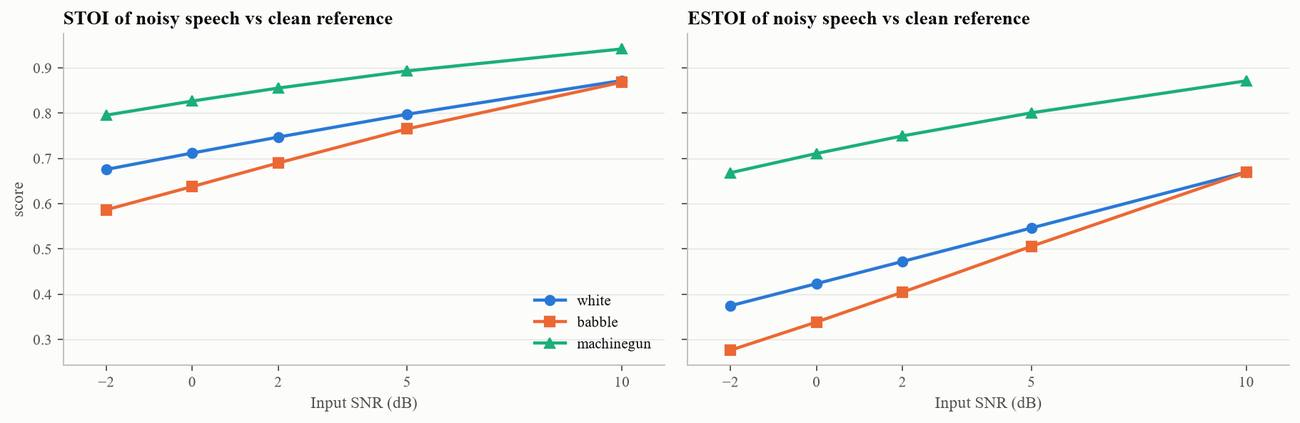

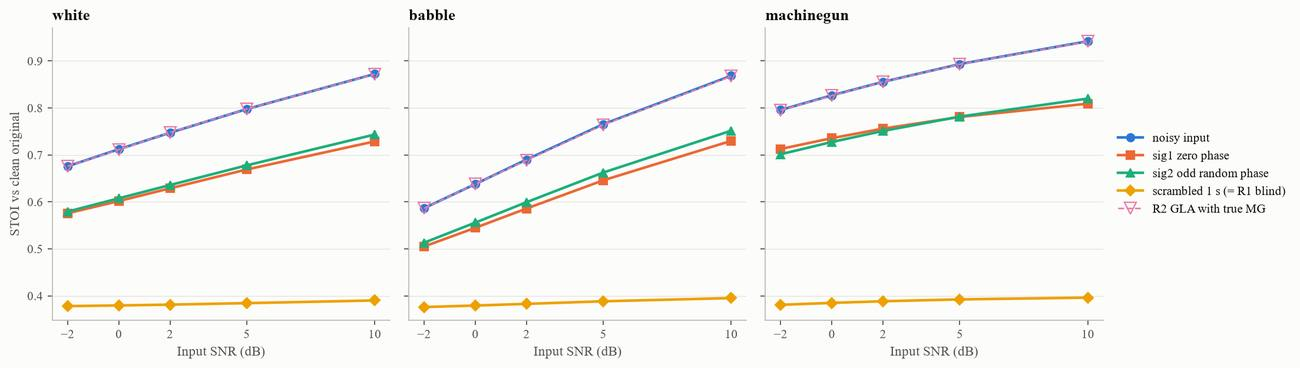

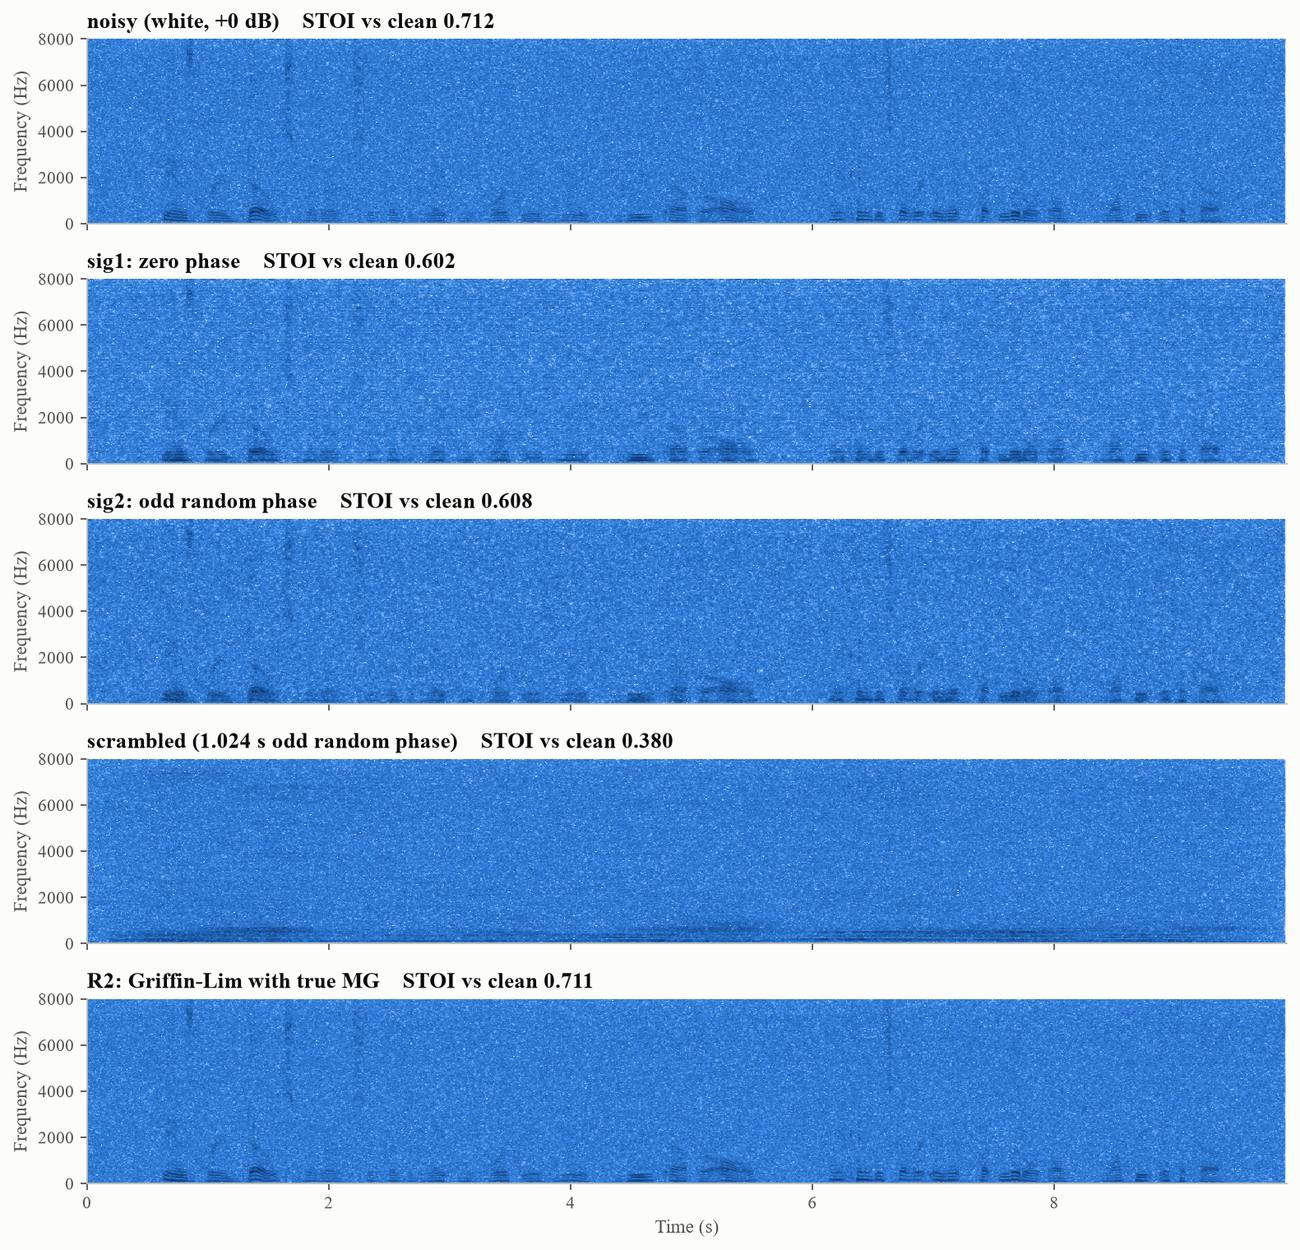

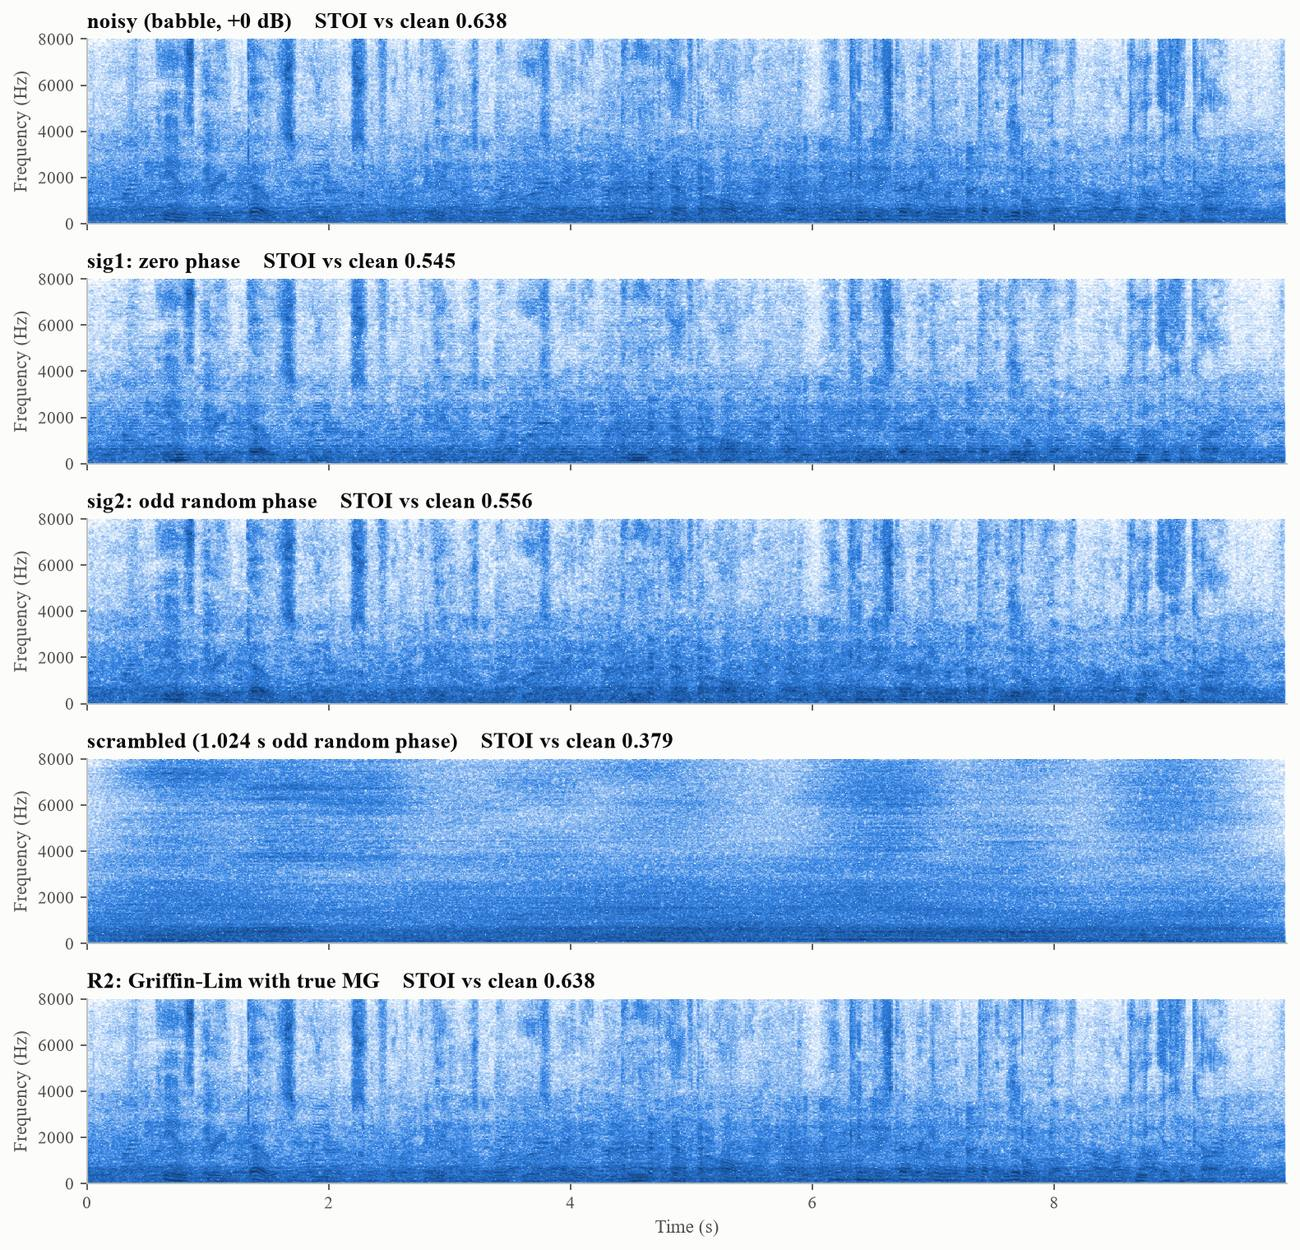

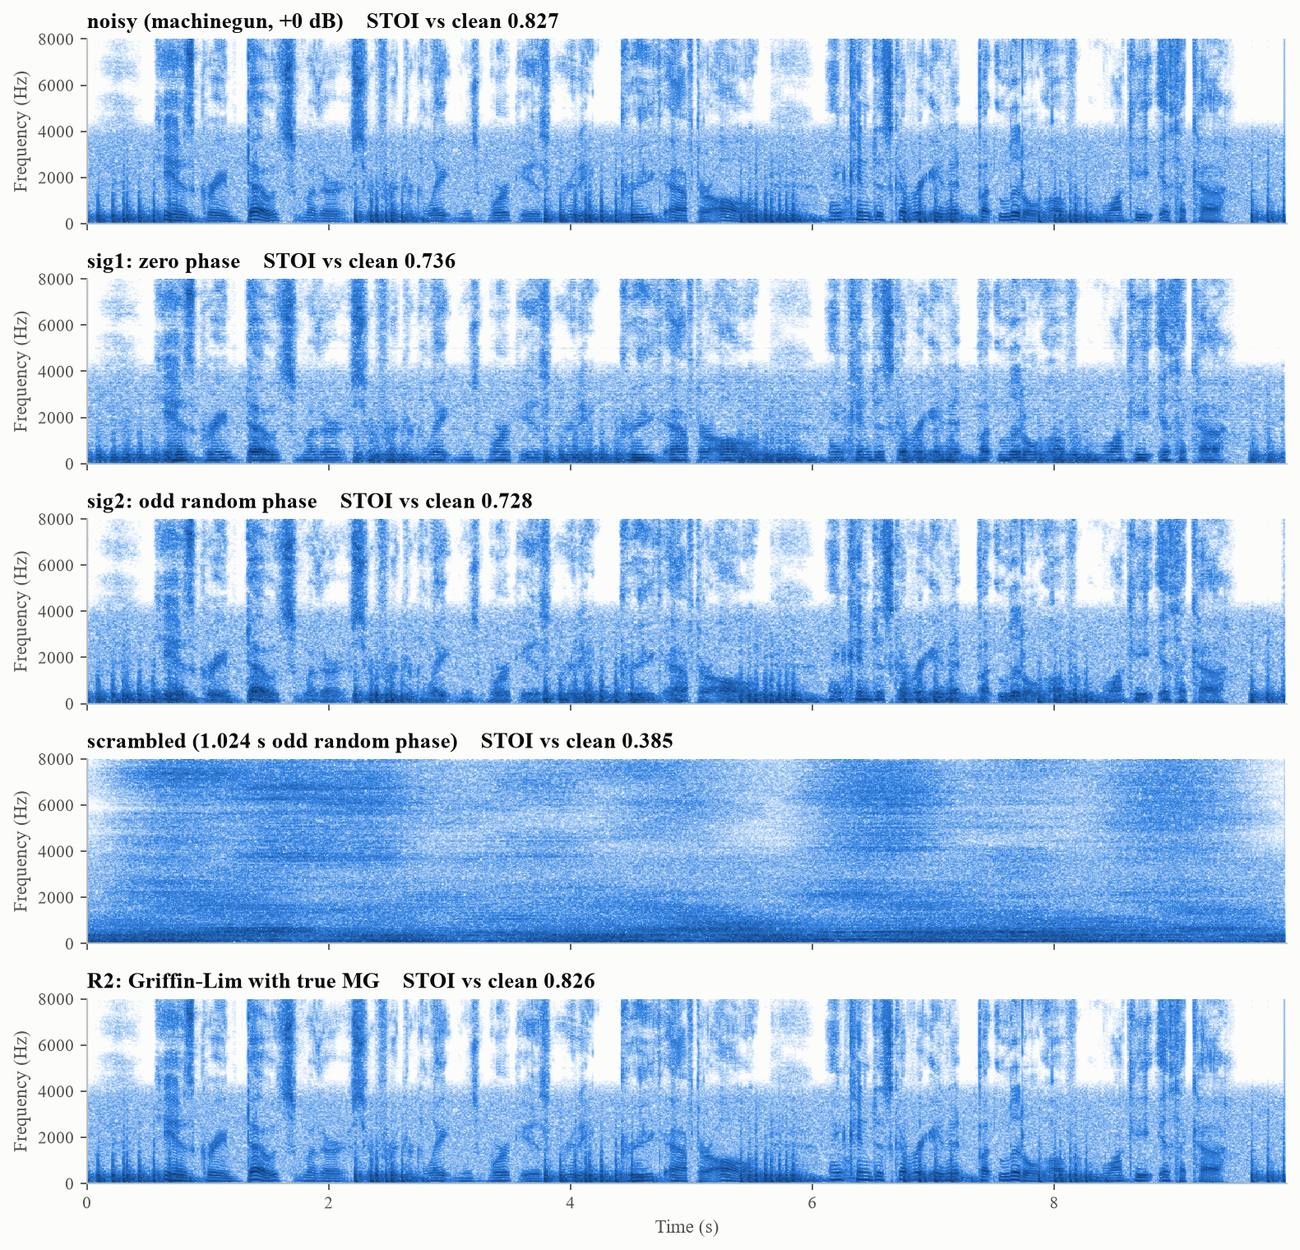

In [11]:
# Questions 2 to 5 for all 15 noisy signals and the band-pass filters take about 20 minutes (run_all.py does the
# same). With RECOMPUTE_PART6 = False the saved results of that run are loaded instead.
RECOMPUTE_PART6 = False
if RECOMPUTE_PART6:
    p6 = E.part6_run_all(x, noisy)
else:
    p6 = {"STOI_wide": pd.read_csv(E.TAB / "p6_STOI_wide.csv", index_col=[0, 1]),
          "ESTOI_wide": pd.read_csv(E.TAB / "p6_ESTOI_wide.csv", index_col=[0, 1]),
          "realness": pd.read_csv(E.TAB / "p6_realness_noisy.csv"),
          "bpf": pd.read_csv(E.TAB / "p6_bpf.csv"),
          "figs": {"stoi_noisy": str(E.FIG / "p6_stoi_noisy.png"),
                   "phase_ops_noise": str(E.FIG / "p6_phase_ops_under_noise.png"),
                   "bpf_stoi": str(E.FIG / "p6_bpf_stoi.png"),
                   **{f"variants_{n}": str(E.FIG / f"p6_variants_{n}_0dB.png") for n in E.NOISES}}}
display(p6["STOI_wide"])
display(p6["ESTOI_wide"])
display(p6["realness"])
for key in ["stoi_noisy", "phase_ops_noise"] + [f"variants_{n}" for n in E.NOISES]:
    show(p6["figs"][key])

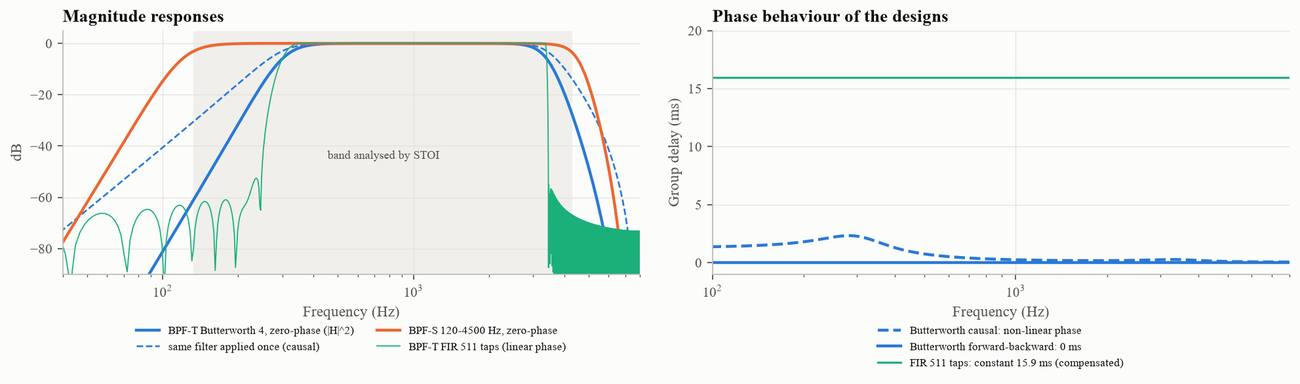

,design,"STOI(clean, BPF(clean))","ESTOI(clean, BPF(clean))",STOI white 0 dB after BPF
0,"Butterworth-4 300-3400, zero-phase (filtfilt)",0.939,0.860,0.653
1,"Butterworth-4 300-3400, causal (sosfilt)",0.974,0.932,0.684
2,"same |H| as causal, zero phase (FFT)",0.975,0.934,0.683
3,"FIR 511 taps 300-3400, linear phase",0.908,0.802,0.638
4,ideal brick-wall 300-3400,0.886,0.734,0.626
5,"Butterworth-4 120-4500, zero-phase",0.996,0.988,0.704
6,"Butterworth-4 500-2500, zero-phase (narrow)",0.910,0.812,0.632
7,ideal brick-wall 500-2500 (narrow),0.729,0.466,0.531


filter             BPF-T  BPF-S  BPF-T brick-wall  oracle Wiener (reference)
noise      SNR_dB                                                           
white      -2      0.619  0.667             0.597                      0.954
            0      0.653  0.704             0.626                      0.960
            2      0.686  0.740             0.654                      0.965
            5      0.735  0.792             0.697                      0.973
            10     0.809  0.868             0.764                      0.982
babble     -2      0.553  0.582             0.528                      0.936
            0      0.600  0.633             0.574                      0.944
            2      0.648  0.684             0.621                      0.953
            5      0.716  0.758             0.686                      0.964
            10     0.811  0.862             0.773                      0.979
machinegun -2      0.757  0.790             0.732                      0.968
            0      0.786  0.821             0.758                      0.973
            2      0.812  0.850             0.781                      0.978
            5      0.847  0.888             0.811                      0.983
            10     0.890  0.936             0.848                      0.990

filter             BPF-T  BPF-S  BPF-T brick-wall  oracle Wiener (reference)
noise      SNR_dB                                                           
white      -2     -0.057 -0.008            -0.079                      0.278
            0     -0.059 -0.008            -0.086                      0.248
            2     -0.061 -0.007            -0.093                      0.218
            5     -0.062 -0.006            -0.101                      0.175
            10    -0.063 -0.005            -0.108                      0.110
babble     -2     -0.033 -0.004            -0.059                      0.349
            0     -0.038 -0.005            -0.063                      0.306
            2     -0.042 -0.006            -0.069                      0.263
            5     -0.049 -0.007            -0.079                      0.199
            10    -0.058 -0.007            -0.096                      0.110
machinegun -2     -0.039 -0.005            -0.064                      0.173
            0     -0.041 -0.006            -0.069                      0.146
            2     -0.043 -0.006            -0.074                      0.122
            5     -0.047 -0.006            -0.082                      0.090
            10    -0.052 -0.006            -0.094                      0.048

filter             BPF-T  BPF-S  BPF-T brick-wall  oracle Wiener (reference)
noise      SNR_dB                                                           
white      -2      1.256  1.889             1.350                     14.683
            0      1.256  1.889             1.350                     13.763
            2      1.256  1.889             1.350                     12.866
            5      1.256  1.889             1.350                     11.571
            10     1.256  1.889             1.350                      9.562
babble     -2     -0.679 -0.444            -0.480                     10.818
            0     -0.679 -0.444            -0.480                      9.969
            2     -0.679 -0.444            -0.480                      9.188
            5     -0.679 -0.444            -0.480                      8.124
            10    -0.679 -0.444            -0.480                      6.571
machinegun -2      4.463  1.148             3.648                     14.895
            0      4.463  1.148             3.648                     13.834
            2      4.463  1.148             3.648                     12.829
            5      4.463  1.148             3.648                     11.439
            10     4.463  1.148             3.648                      9.439

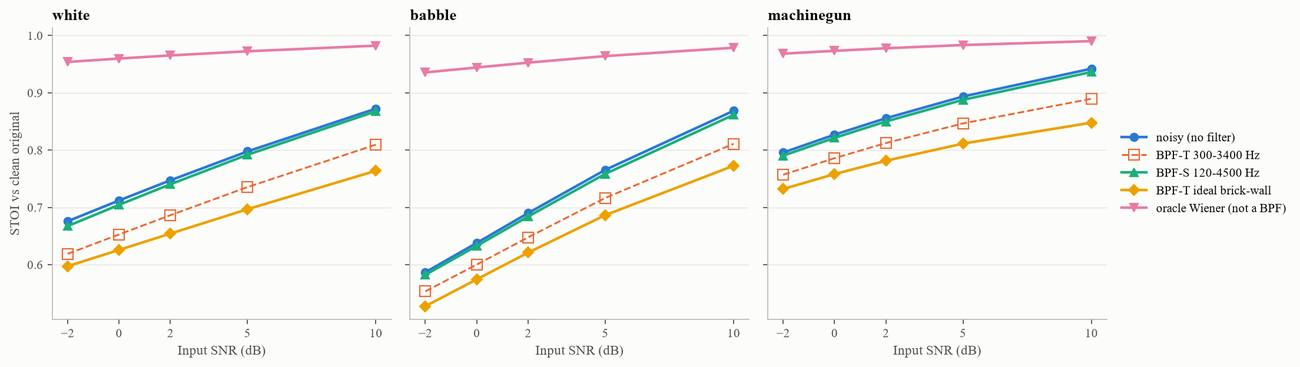

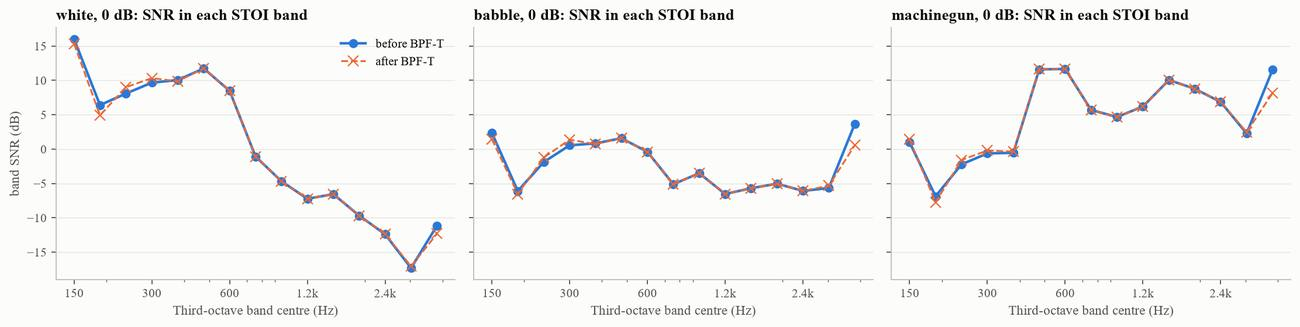

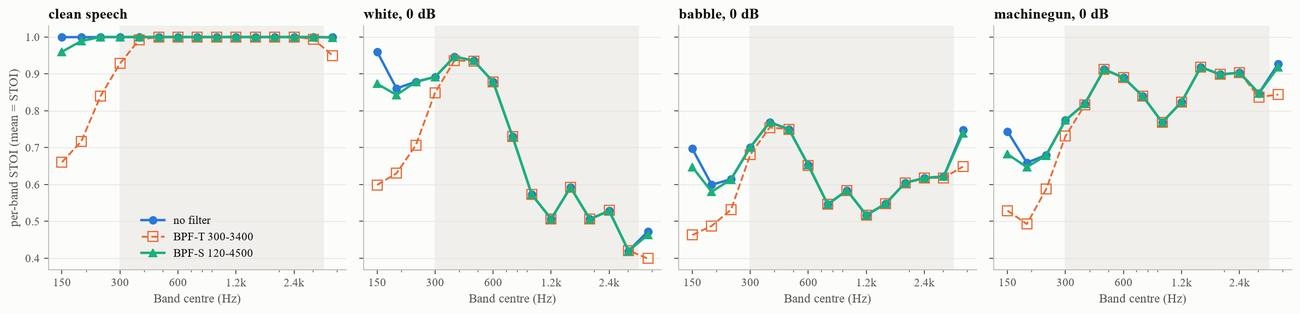

noisy -> outputs/audio/white_p0dB/noisy.wav
bpf_telephone_300_3400 -> outputs/audio/white_p0dB/bpf_telephone_300_3400.wav
bpf_stoi_band_120_4500 -> outputs/audio/white_p0dB/bpf_stoi_band_120_4500.wav
oracle_wiener -> outputs/audio/white_p0dB/oracle_wiener.wav


In [12]:
fd = E.part6_filter_design(x, noisy)
show(fd["figs"]["bpf_design"])
display(fd["diagnostics"])
b = p6["bpf"]
for value in ["STOI", "dSTOI", "SNR gain (dB)"]:
    display(b.pivot_table(index=["noise", "SNR_dB"], columns="filter", values=value, sort=False))
show(p6["figs"]["bpf_stoi"])
show(fd["figs"]["band_snr"])
bc = E.part6_band_contrib(x, noisy)
show(bc["figs"]["band_stoi"])
for name in ["noisy", "bpf_telephone_300_3400", "bpf_stoi_band_120_4500", "oracle_wiener"]:
    play("white_p0dB", name)

A fixed band-pass filter multiplies speech and noise by the same gain at every frequency, so the SNR inside each
pass-band third-octave band, which is what STOI measures after its per-band normalisation, does not change. The filter
raises the broadband SNR but cannot raise STOI; it can only lower it by removing STOI bands. Only a time-varying gain
(the oracle Wiener reference) improves STOI.